# APPLE STOCK PRICE PREDICTION - for next 30 days

# EDA

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore", category = DeprecationWarning)

In [ ]:
df = pd.read_csv("/content/Dataset.csv")
df.head()

,Date,Open,High,Low,Close,Adj Close,Volume
0,2012-01-03,58.485714,58.928570,58.428570,58.747143,50.765709,75555200
1,2012-01-04,58.571430,59.240002,58.468571,59.062859,51.038536,65005500
2,2012-01-05,59.278572,59.792858,58.952858,59.718571,51.605175,67817400
3,2012-01-06,59.967144,60.392857,59.888573,60.342857,52.144630,79573200
4,2012-01-09,60.785713,61.107143,60.192856,60.247143,52.061932,98506100


In [ ]:
df.shape

(2011, 7)

In [ ]:
df.size

14077

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2011 entries, 0 to 2010
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       2011 non-null   object 
 1   Open       2011 non-null   float64
 2   High       2011 non-null   float64
 3   Low        2011 non-null   float64
 4   Close      2011 non-null   float64
 5   Adj Close  2011 non-null   float64
 6   Volume     2011 non-null   int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 110.1+ KB


In [ ]:
#Converting the Date column into datetime
df['Date'] = pd.to_datetime(df['Date'])

In [ ]:
#Verifying the conversion
df['Date'].dtype

dtype('<M8[ns]')

In [ ]:
df.sort_values('Date')

,Date,Open,High,Low,Close,Adj Close,Volume
0,2012-01-03,58.485714,58.928570,58.428570,58.747143,50.765709,75555200
1,2012-01-04,58.571430,59.240002,58.468571,59.062859,51.038536,65005500
2,2012-01-05,59.278572,59.792858,58.952858,59.718571,51.605175,67817400
3,2012-01-06,59.967144,60.392857,59.888573,60.342857,52.144630,79573200
4,2012-01-09,60.785713,61.107143,60.192856,60.247143,52.061932,98506100
...,...,...,...,...,...,...,...
2006,2019-12-23,280.529999,284.250000,280.369995,284.000000,282.054138,24643000
2007,2019-12-24,284.690002,284.890015,282.920013,284.269989,282.322266,12119700
2008,2019-12-26,284.820007,289.980011,284.700012,289.910004,287.923645,23280300
2009,2019-12-27,291.119995,293.970001,288.119995,289.799988,287.814392,36566500


In [ ]:
print("First Date: ",
df['Date'].min())
print("Last Date: ",
df['Date'].max())

First Date:  2012-01-03 00:00:00
Last Date:  2019-12-30 00:00:00


In [ ]:
#Checking null values
df.isnull().sum()

,0
Date,0
Open,0
High,0
Low,0
Close,0
Adj Close,0
Volume,0


In [ ]:
#Checking duplicate values
df.duplicated().sum()

np.int64(0)

In [ ]:
df.describe()

,Date,Open,High,Low,Close,Adj Close,Volume
count,2011,2011.000000,2011.000000,2011.000000,2011.000000,2011.000000,2.011000e+03
mean,2016-01-01 03:10:28.344107520,126.707469,127.827594,125.580258,126.741235,119.505548,5.949670e+07
min,2012-01-03 00:00:00,55.424286,57.085712,55.014286,55.790001,48.921928,1.136200e+07
25%,2014-01-02 12:00:00,85.882858,86.717858,85.056427,86.202145,75.056679,2.758565e+07
50%,2015-12-31 00:00:00,113.050003,114.190002,111.870003,113.050003,105.222908,4.346900e+07
75%,2017-12-28 12:00:00,165.190002,167.409996,163.424995,165.245002,160.047111,7.471030e+07
max,2019-12-30 00:00:00,291.119995,293.970001,288.119995,291.519989,289.522614,3.765300e+08
std,NaN,50.483753,50.926301,50.124940,50.578369,52.438444,4.683856e+07


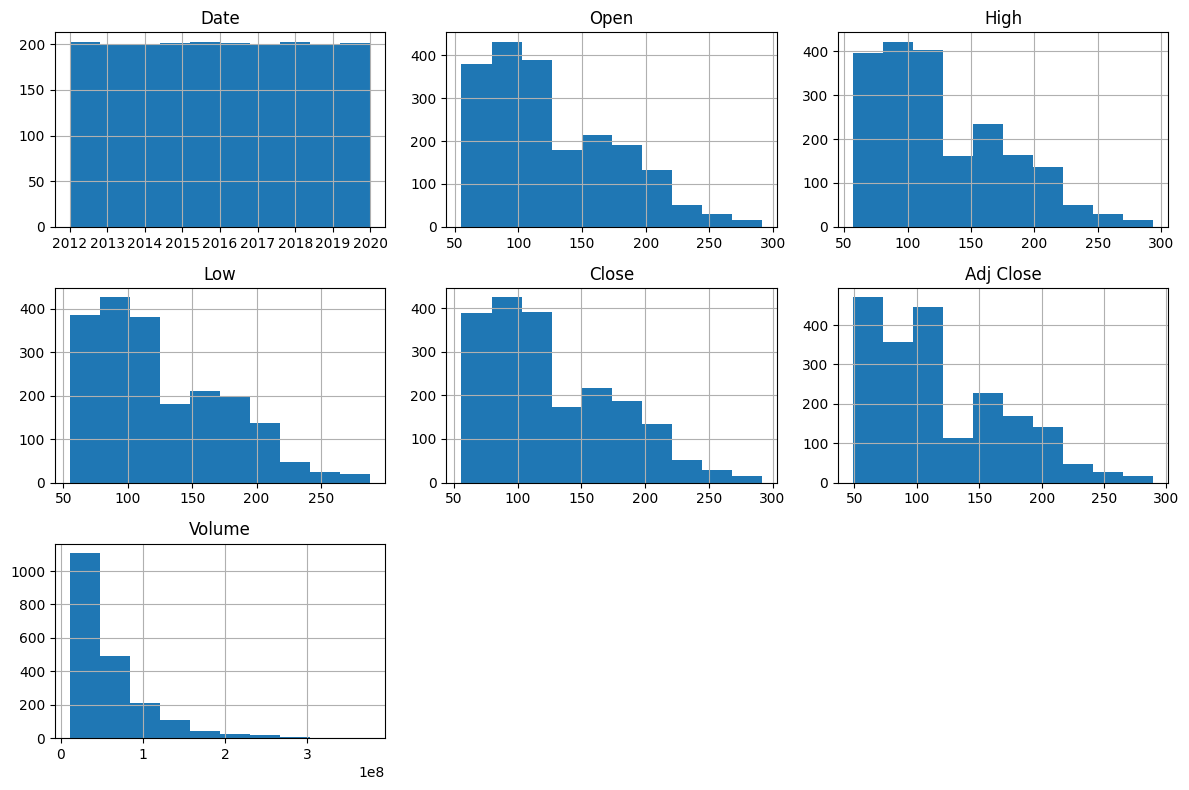

In [ ]:
#Checking the distribution
df.hist(figsize=(12,8))
plt.tight_layout()
plt.show()

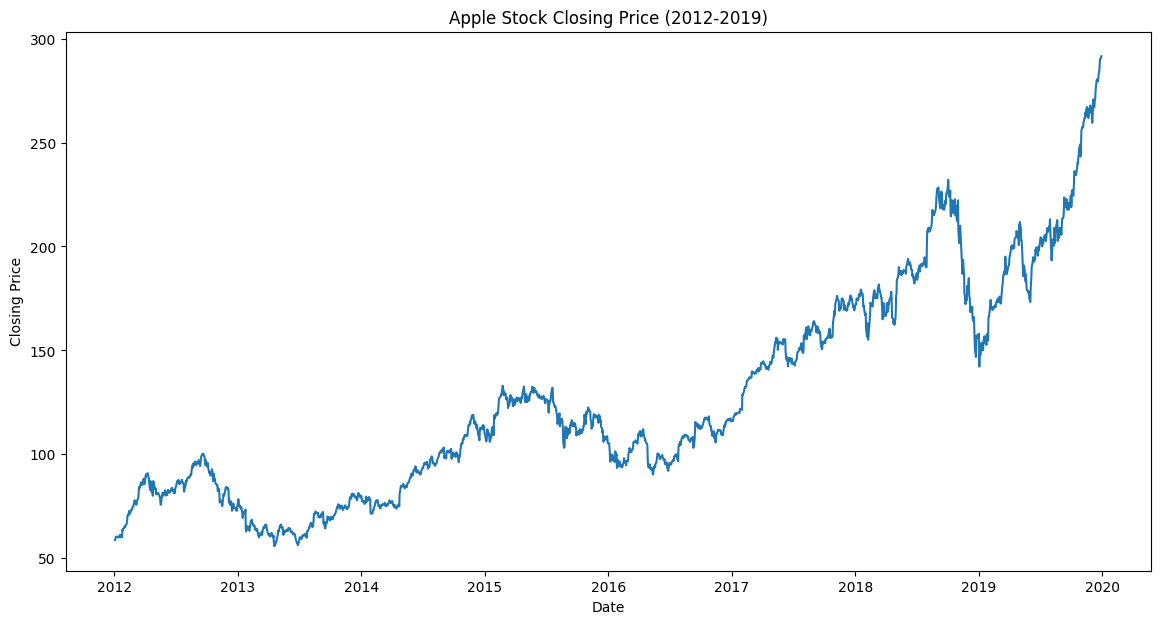

In [ ]:
#Plotting Apple's closing price over time
plt.figure(figsize=(14,7))
plt.plot(df['Date'], df['Close'])
plt.title("Apple Stock Closing Price (2012-2019)")
plt.xlabel('Date')
plt.ylabel('Closing Price')
plt.show()

The closing price visualization shows an overall upward trend in Apple's stock prices from 2012 to 2019. Although fluctuations occurred during the period, the general direction was positive, indicating long-term price growth.

In [ ]:
#Analyze the correlation between numerical variables

In [ ]:
#Creating a correlation matrix
df[['Open','High','Low','Close','Adj Close','Volume']].corr()

,Open,High,Low,Close,Adj Close,Volume
Open,1.000000,0.999782,0.999718,0.999496,0.998895,-0.557956
High,0.999782,1.000000,0.999657,0.999748,0.999171,-0.554909
Low,0.999718,0.999657,1.000000,0.999769,0.999179,-0.563426
Close,0.999496,0.999748,0.999769,1.000000,0.999402,-0.559654
Adj Close,0.998895,0.999171,0.999179,0.999402,1.000000,-0.566332
Volume,-0.557956,-0.554909,-0.563426,-0.559654,-0.566332,1.000000


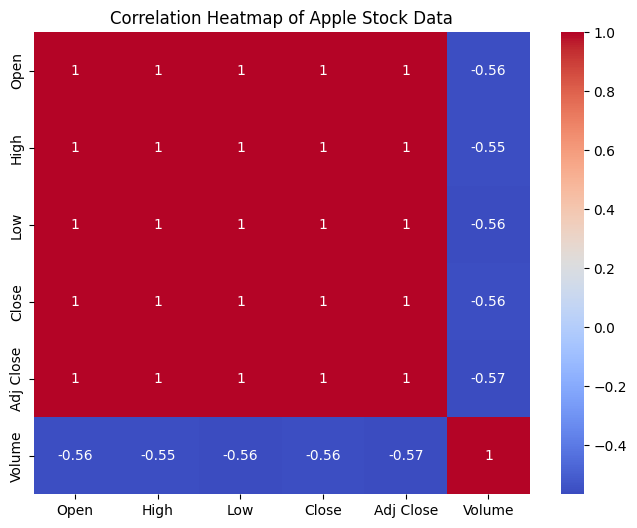

In [ ]:
#Visualise it using a heatmap
plt.figure(figsize=(8,6))
sns.heatmap(
    df[['Open','High','Low','Close','Adj Close','Volume']].corr(),
    annot=True,
    cmap = 'coolwarm'
)
plt.title("Correlation Heatmap of Apple Stock Data")
plt.show()

The correlation heatmap shows a strong positive relationship among Apple's opening, highest,lowest, closing and adjusted closing prices. Trading volume exhibits a moderate negative correlation with these price variable. These findings indicate that the price variables move closely together while trading volume follows a different pattern during the analyzed period.

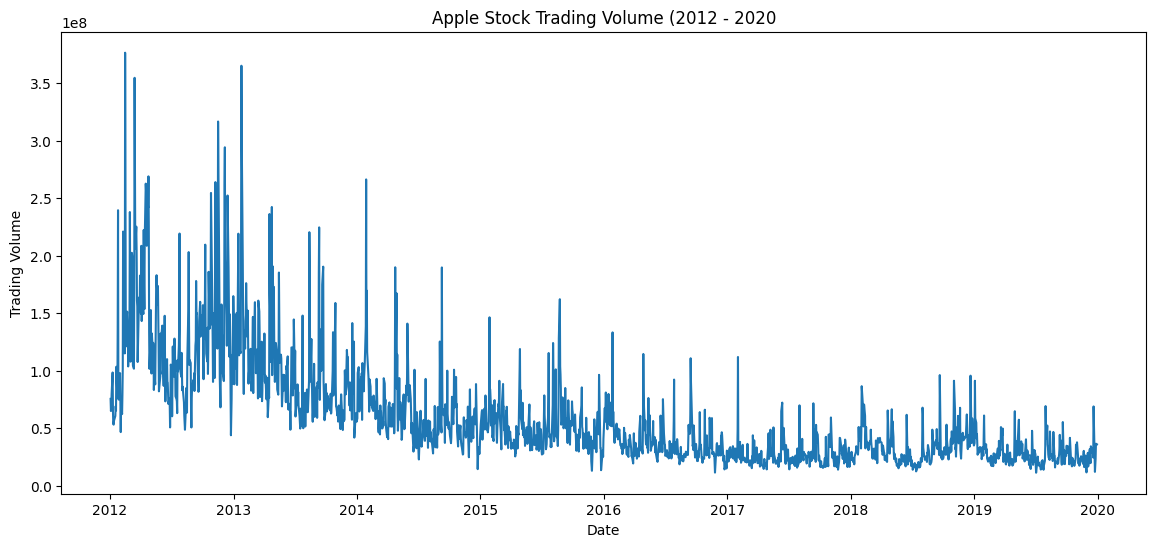

In [ ]:
#Analyze the trading volume
plt.figure(figsize=(14,6))
plt.plot(df['Date'],df['Volume'])
plt.title('Apple Stock Trading Volume (2012 - 2020')
plt.xlabel('Date')
plt.ylabel('Trading Volume')
plt.show()

The trading volume visualization shows substantial fluctuations in Apple's daily trading activity between 2012-2019. Trading volume was generally higher and more volatile during 2012-2013, followed by a decline in typical volume in subsequent years. Occasional spikes were observed throughout the period, indicating days with high trading activity.

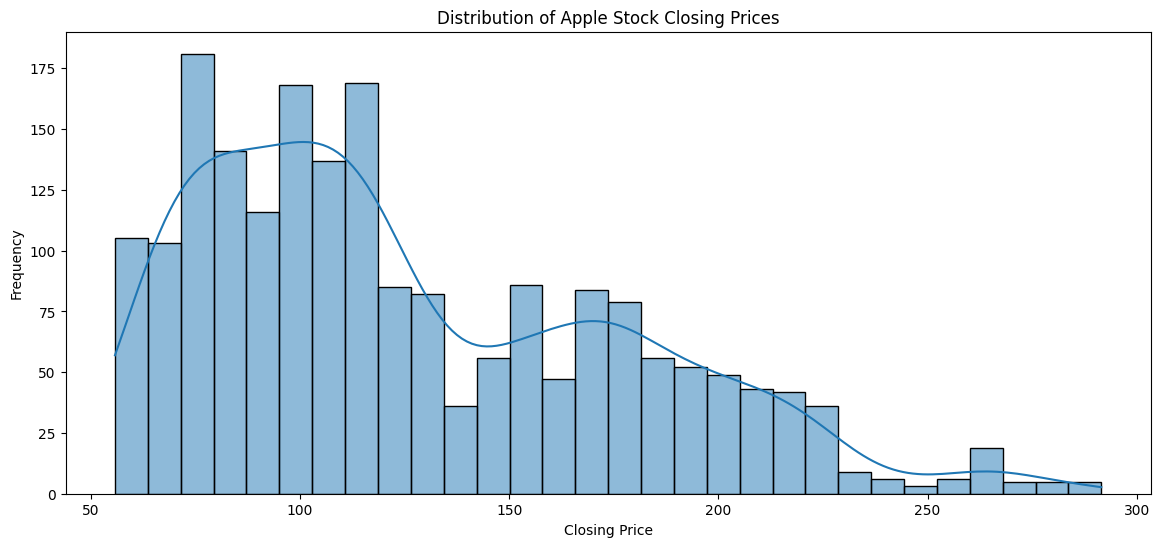

In [ ]:
#Analyze the distribution of closing price
plt.figure(figsize=(14,6))
sns.histplot(df['Close'], bins=30, kde=True)
plt.title('Distribution of Apple Stock Closing Prices')
plt.xlabel('Closing Price')
plt.ylabel('Frequency')
plt.show()

*  The distribution is positively skewed.
*  The highest bars appears around $70-$80, with other high-frequency ranges around $90-$120.

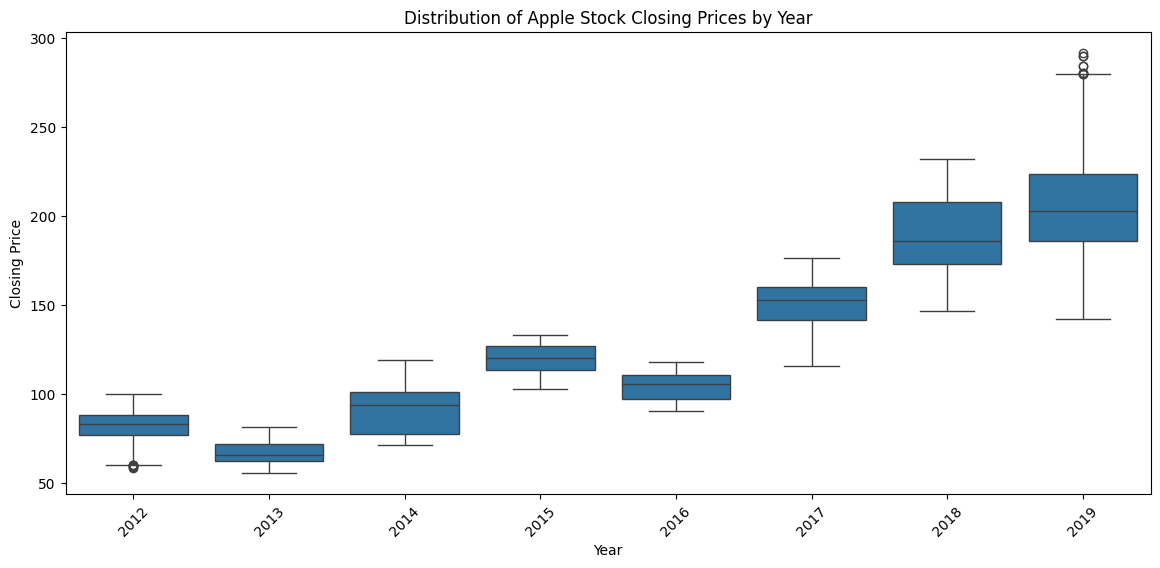

In [ ]:
#Analyze the closing prices by year
df['Year'] = df['Date'].dt.year
plt.figure(figsize=(14,6))
sns.boxplot(data = df, x='Year', y='Close')
plt.title("Distribution of Apple Stock Closing Prices by Year")
plt.xlabel('Year')
plt.ylabel('Closing Price')
plt.xticks(rotation=45)
plt.show()

In [ ]:
df.groupby(df['Date'].dt.year)['Close'].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
Date,,,,,,,,
2012,250.0,82.29,9.57,58.75,76.98,83.21,88.20,100.30
2013,252.0,67.52,6.41,55.79,62.54,65.87,72.16,81.44
2014,252.0,92.26,13.37,71.40,77.69,93.90,101.12,119.00
2015,252.0,120.04,7.68,103.12,113.37,120.30,126.91,133.00
2016,252.0,104.60,7.64,90.34,97.14,105.75,110.98,118.25
2017,251.0,150.55,14.62,116.02,141.82,152.74,159.86,176.42
2018,251.0,189.05,20.59,146.83,173.14,186.05,207.76,232.07
2019,251.0,207.92,34.18,142.19,185.92,202.90,223.34,291.52


The year-wise descriptive statistics indicate that Apple's average closing price generally increased between 2013 and 2019, with temporary declines in 2013 and 2016. Price variability also increased in 2018 and 2019, as reflected by higher standard deviations. These results highlight long-term price growth alongside fluctuations in stock prices.

In [ ]:
#Checking the date range and frequency
print("Start Date: ", df['Date'].min())
print("End Date: ",df['Date'].max())

print("Total Records: ", len(df))
print("Unique Dates: ", df['Date'].nunique())

print("Dates sorted:",df['Date'].is_monotonic_increasing)

Start Date:  2012-01-03 00:00:00
End Date:  2019-12-30 00:00:00
Total Records:  2011
Unique Dates:  2011
Dates sorted: True


In [ ]:
#Checking the distribution of daily price columns
df[['Open','High','Low','Close','Adj Close','Volume']].skew().round(2)

,0
Open,0.77
High,0.77
Low,0.77
Close,0.77
Adj Close,0.79
Volume,2.17


The skewness analysis revealed that Open, High, Low and Close variables have moderately positive skewness, while Volume has a strong positive skewness of 2.17. This indicates that trading volume has a longer right tail, potentially due to occassional days with unusually high trading activity.

In [ ]:
#Checking the relationship between Open, High, Low and Close
print("Days where High < Low:")
print((df['High'] < df['Low']).sum())

print("Days where High < Open:")
print((df['High'] < df['Open']).sum())

print("Days where High > Close:")
print((df['High'] < df['Close']).sum())

print("Days where Low > Open:")
print((df['Low'] > df['Open']).sum())

print("Days where Low > Close:")
print((df['Low'] > df['Close']).sum())

Days where High < Low:
0
Days where High < Open:
0
Days where High > Close:
0
Days where Low > Open:
0
Days where Low > Close:
0


This helps identify incosistent price records.

In [ ]:
#Analysing yearly average closing prices
yearly_avg = df.groupby(df['Date'].dt.year)['Close'].mean()
print(yearly_avg.round(2))

Date
2012     82.29
2013     67.52
2014     92.26
2015    120.04
2016    104.60
2017    150.55
2018    189.05
2019    207.92
Name: Close, dtype: float64


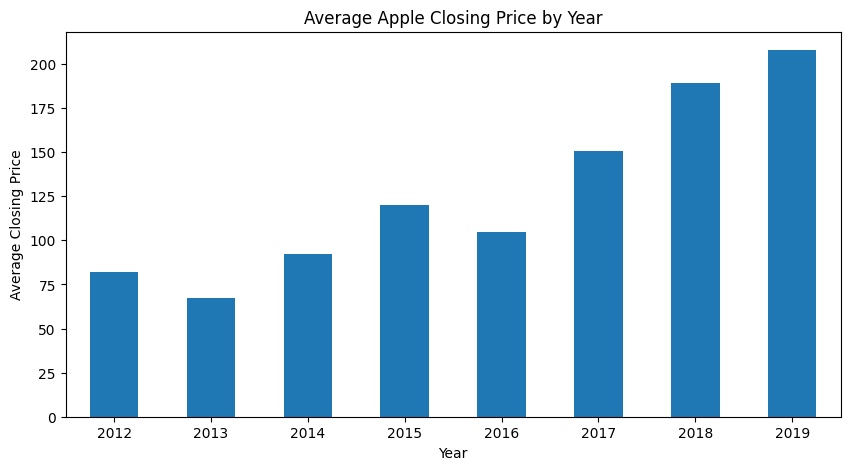

In [ ]:
#Visualizing yearly average closing prices
yearly_avg.plot(kind='bar',figsize=(10,5))
plt.title('Average Apple Closing Price by Year')
plt.xlabel('Year')
plt.ylabel('Average Closing Price')
plt.xticks(rotation=0)
plt.show()

The yearly average closing price analysis reveals on overall upward trend in Apple's stock prices from 2012 to 2019. Although declines occured in 2013 and 2016, the average closing price increased substantially in subsequent years, reaching its highest yearly average in 2019.

In [ ]:
numeric_cols = df.select_dtypes(include='number').columns
for col in numeric_cols:
  q1 = df[col].quantile(0.25)
  q3 = df[col].quantile(0.75)
  IQR = q3 - q1
  lower_bound = q1 - 1.5 * IQR
  upper_bound = q3 + 1.5 * IQR
  outliers = df[
      (df[col] < lower_bound) |
      (df[col] > upper_bound)
  ]
  print(f"{col}: {len(outliers)} potential outliers")

Open: 4 potential outliers
High: 3 potential outliers
Low: 4 potential outliers
Close: 5 potential outliers
Adj Close: 3 potential outliers
Volume: 127 potential outliers
Year: 0 potential outliers


In [ ]:
#Checking the monthly seasonality : whether average closing prices show any recurring patterns across calendar months.
monthly_avg = df.groupby(df['Date'].dt.month)['Close'].mean()
print(monthly_avg.round(2))

Date
1     108.57
2     112.84
3     119.13
4     120.97
5     123.23
6     123.55
7     126.24
8     132.77
9     135.17
10    139.26
11    140.54
12    136.99
Name: Close, dtype: float64


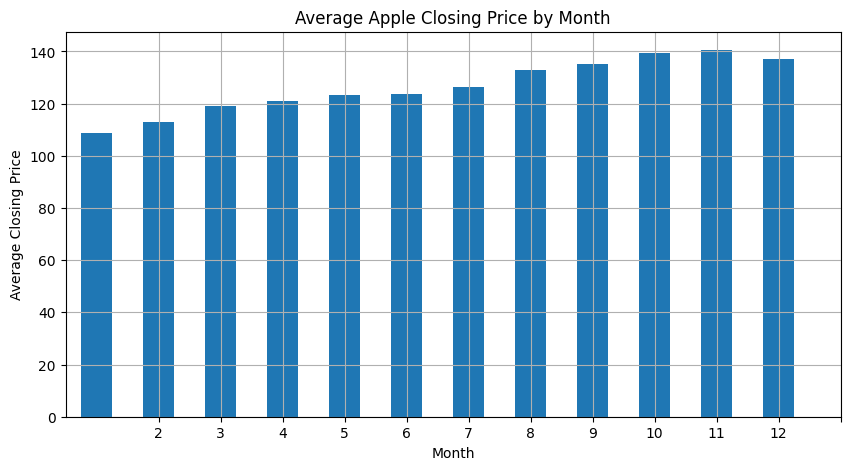

In [ ]:
#Visualizing monthly averages
monthly_avg.plot(kind='bar', figsize=(10,5))
plt.title("Average Apple Closing Price by Month")
plt.xlabel('Month')
plt.ylabel('Average Closing Price')
plt.xticks(range(1,13), rotation = 0)
plt.grid(True)
plt.show()

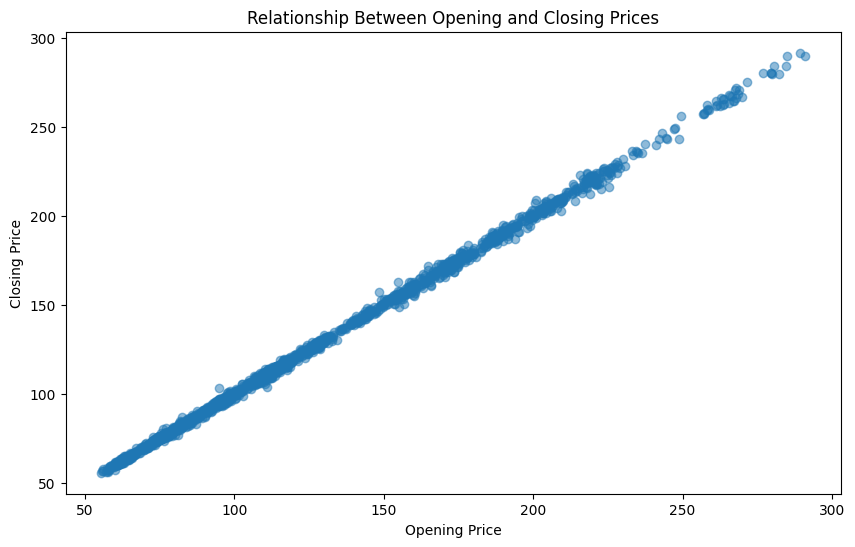

In [ ]:
#Analyzing the daily relationship between opening and closing prices
plt.figure(figsize=(10,6))
plt.scatter(df['Open'],df['Close'], alpha = 0.5)
plt.title('Relationship Between Opening and Closing Prices')
plt.xlabel('Opening Price')
plt.ylabel('Closing Price')
plt.show()

The Scatter Plot reveals a very strong positive relationship between Apple's opening and closing prices. The data points closely follow a linear pattern, indicating that higher opening prices are generally associated with higher closing prices across the observation period.

# Feature Engineering


In [ ]:
#Checking if the data is stationary or not
from statsmodels.tsa.stattools import adfuller
result = adfuller(df['Close'])
print('ADF Statistics: ',result[0])
print('p-value: ',result[1])
print('Critical value: ', result[4])

ADF Statistics:  1.2193701254378007
p-value:  0.9961170178032009
Critical value:  {'1%': np.float64(-3.433622218212895), '5%': np.float64(-2.8629854902259004), '10%': np.float64(-2.5675395171404802)}


/tmp/ipykernel_2637/846180115.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(df['Close'])


So, the p-value is 0.99. the p-value is greater than 0.05. so, we fail to reject the null hypothesis. which means the close column data is not stationary.

Now, will apply first-order differencing on the closing price series and will perform the  ADF test again.

**First-Order differencing on Closing Price**

In [ ]:
#Applying first-order differencing
df_diff = df['Close'].diff().dropna()

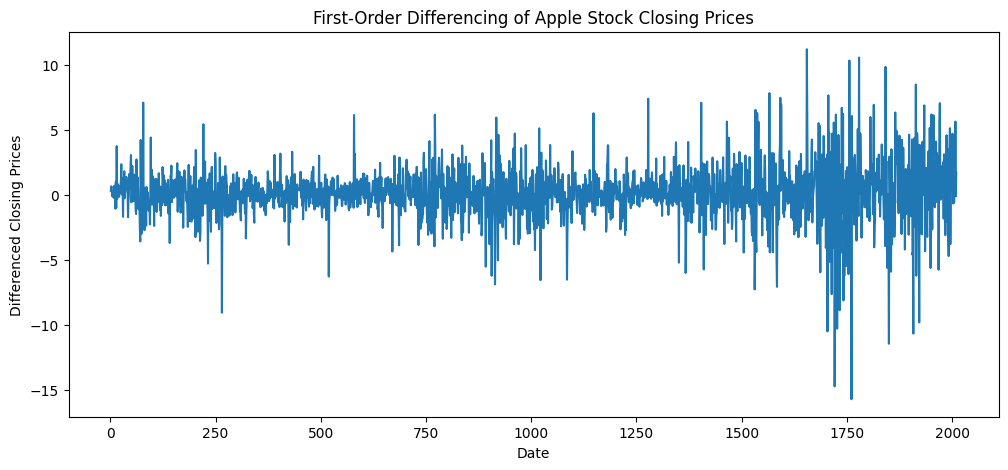

In [ ]:
#Visulaizing the first-order differencing
df_diff.plot(figsize=(12,5))
plt.title('First-Order Differencing of Apple Stock Closing Prices')
plt.xlabel('Date')
plt.ylabel('Differenced Closing Prices')
plt.show()

In [ ]:
#Checking stationary again
result_diff = adfuller(df_diff)
print('ADF Statistics:',result_diff[0])
print('p-value:',result_diff[1])

ADF Statistics: -13.625534323873257
p-value: 1.7631231987209532e-25


/tmp/ipykernel_2637/701253924.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result_diff = adfuller(df_diff)


Since, now the p-value is 0.00 , we reject the null hypothesis. and the closing price is now stationary after applying first order differencing and calculating it by adfuller test

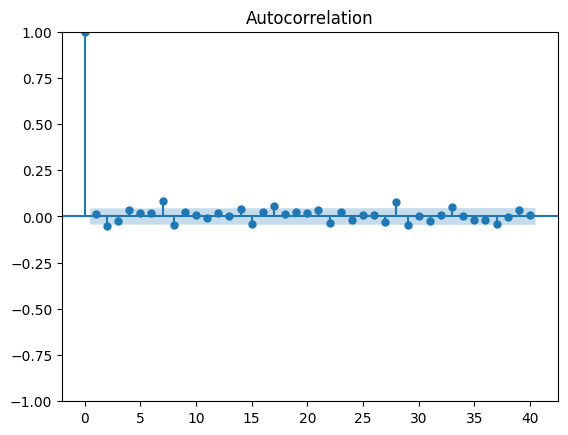

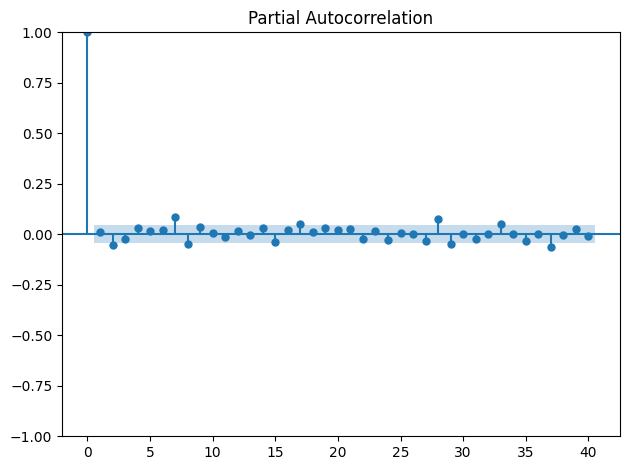

In [ ]:
#ACF and PACF
from statsmodels.graphics.tsaplots import plot_acf,plot_pacf
plot_acf(df_diff,lags =40)

plot_pacf(df_diff, lags=40)

plt.tight_layout()
plt.show()

In [ ]:
from statsmodels.tsa.stattools import acf, pacf

acf_values = acf(df_diff, nlags=40)
pacf_values = pacf(df_diff, nlags=40)

print("ACF values:")
print(acf_values)

print("PACF Values")
print(pacf_values)

ACF values:
[ 1.00000000e+00  1.12310418e-02 -5.32683890e-02 -2.29107417e-02
  3.31526467e-02  1.92272647e-02  1.97165502e-02  8.12126641e-02
 -4.78043039e-02  2.66846543e-02  9.83896332e-03 -7.62378662e-03
  1.61448186e-02  2.26812849e-03  3.82507813e-02 -4.23776040e-02
  2.33213368e-02  5.41579843e-02  1.38305014e-02  2.61516164e-02
  1.88692514e-02  3.32373845e-02 -3.27586473e-02  2.21795464e-02
 -1.69388906e-02  5.84414026e-03  1.02757999e-02 -2.96345964e-02
  7.71690973e-02 -4.80724638e-02  3.44872679e-04 -2.51693289e-02
  7.81330622e-03  5.18150382e-02  4.79162624e-03 -2.11492665e-02
 -2.15729718e-02 -4.09180048e-02 -3.14656301e-03  3.33207044e-02
  9.04252766e-03]
PACF Values
[ 1.00000000e+00  1.12366322e-02 -5.34544564e-02 -2.17781293e-02
  3.09789065e-02  1.62602476e-02  2.23427078e-02  8.47542233e-02
 -4.82431332e-02  3.68463833e-02  6.13541422e-03 -1.33414229e-02
  1.89351719e-02 -2.69553052e-03  3.35074616e-02 -3.61561743e-02
  2.01359197e-02  5.38894298e-02  1.11957365e-02

After first-order differencing,I performed acf and pacf plot to know the AR and MA , but the correlation values are very close to ecah other. there are few significant spikes for individual lags. So, the plot did not show the clear cut-off pattern.

Therefore, I will evaluate multiple combinations of p and q to indentify AR and MA

In [ ]:
#creating a copy of dataset
df_fe = df.copy()

In [ ]:
#Extracting date features
df_fe['Date'] = pd.to_datetime(df_fe['Date'])
df_fe['Year'] = df_fe['Date'].dt.year
df_fe['Month'] = df_fe['Date'].dt.month
df_fe['Day'] = df_fe['Date'].dt.day
df_fe['DayOfWeek']=df_fe['Date'].dt.dayofweek

In [ ]:
df_fe[['Date','Year','Month','Day','DayOfWeek']].head()

,Date,Year,Month,Day,DayOfWeek
0,2012-01-03,2012,1,3,1
1,2012-01-04,2012,1,4,2
2,2012-01-05,2012,1,5,3
3,2012-01-06,2012,1,6,4
4,2012-01-09,2012,1,9,0


**Creating Lag Features**

In [ ]:
#Creating the first three lag features
df_fe['Close_Lag_1'] = df_fe['Close'].shift(1)
df_fe['Close_Lag_2'] = df_fe['Close'].shift(2)
df_fe['Close_Lag_3'] = df_fe['Close'].shift(3)

#Checking the Output
df_fe[['Date','Close','Close_Lag_1','Close_Lag_2','Close_Lag_3']].head(7)

,Date,Close,Close_Lag_1,Close_Lag_2,Close_Lag_3
0,2012-01-03,58.747143,NaN,NaN,NaN
1,2012-01-04,59.062859,58.747143,NaN,NaN
2,2012-01-05,59.718571,59.062859,58.747143,NaN
3,2012-01-06,60.342857,59.718571,59.062859,58.747143
4,2012-01-09,60.247143,60.342857,59.718571,59.062859
5,2012-01-10,60.462856,60.247143,60.342857,59.718571
6,2012-01-11,60.364285,60.462856,60.247143,60.342857


Created lag features , because it help models like AdaBoost and XGBoost learn patterns from past stock prices.

**Creating three features**

In [ ]:
#Creating rolling mean features
df_fe['Rolling_Mean_7'] = df_fe['Close'].shift(1).rolling(window=7).mean()
df_fe['Rolling_Mean_14'] = df_fe['Close'].shift(2).rolling(window=14).mean()
df_fe['Rolling_Mean_30'] = df_fe['Close'].shift(3).rolling(window=30).mean()

df_fe[['Date','Close','Rolling_Mean_7','Rolling_Mean_14','Rolling_Mean_30']].head(35)

,Date,Close,Rolling_Mean_7,Rolling_Mean_14,Rolling_Mean_30
0,2012-01-03,58.747143,NaN,NaN,NaN
1,2012-01-04,59.062859,NaN,NaN,NaN
2,2012-01-05,59.718571,NaN,NaN,NaN
3,2012-01-06,60.342857,NaN,NaN,NaN
4,2012-01-09,60.247143,NaN,NaN,NaN
5,2012-01-10,60.462856,NaN,NaN,NaN
6,2012-01-11,60.364285,NaN,NaN,NaN
7,2012-01-12,60.198570,59.849388,NaN,NaN
8,2012-01-13,59.972858,60.056734,NaN,NaN
9,2012-01-17,60.671429,60.186734,NaN,NaN


In [ ]:
#Creating Daily Price Change feature
df_fe['Daily_Change'] = df_fe['Close'] - df_fe['Close'].shift(1)

df_fe[['Date','Close','Daily_Change']].head(10)

,Date,Close,Daily_Change
0,2012-01-03,58.747143,NaN
1,2012-01-04,59.062859,0.315716
2,2012-01-05,59.718571,0.655712
3,2012-01-06,60.342857,0.624286
4,2012-01-09,60.247143,-0.095714
5,2012-01-10,60.462856,0.215713
6,2012-01-11,60.364285,-0.098571
7,2012-01-12,60.198570,-0.165715
8,2012-01-13,59.972858,-0.225712
9,2012-01-17,60.671429,0.698571


In [ ]:
#Creating Daily Percentage Change Feature
df_fe['Daily_Pct_Change'] = (
    df_fe['Close'].pct_change() * 100
)

df_fe[['Date','Close','Daily_Change','Daily_Pct_Change']].head(10)

,Date,Close,Daily_Change,Daily_Pct_Change
0,2012-01-03,58.747143,NaN,NaN
1,2012-01-04,59.062859,0.315716,0.537415
2,2012-01-05,59.718571,0.655712,1.110193
3,2012-01-06,60.342857,0.624286,1.045380
4,2012-01-09,60.247143,-0.095714,-0.158617
5,2012-01-10,60.462856,0.215713,0.358047
6,2012-01-11,60.364285,-0.098571,-0.163027
7,2012-01-12,60.198570,-0.165715,-0.274525
8,2012-01-13,59.972858,-0.225712,-0.374946
9,2012-01-17,60.671429,0.698571,1.164812


**Creating High-Low Difference Feature**

It will calculate the difference between highest and lowest prices recorded during each trading day.

In [ ]:
#Creating High-Low Difference Feature
df_fe['High_Low_Difference'] = df_fe['High'] - df_fe['Low']

df_fe[['Date','High','Low','High_Low_Difference']].head()

,Date,High,Low,High_Low_Difference
0,2012-01-03,58.928570,58.428570,0.500000
1,2012-01-04,59.240002,58.468571,0.771431
2,2012-01-05,59.792858,58.952858,0.840000
3,2012-01-06,60.392857,59.888573,0.504284
4,2012-01-09,61.107143,60.192856,0.914287


In [ ]:
#Checking all the columns
df_fe.columns

Index(['Date', 'Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume', 'Year',
       'Month', 'Day', 'DayOfWeek', 'Close_Lag_1', 'Close_Lag_2',
       'Close_Lag_3', 'Rolling_Mean_7', 'Rolling_Mean_14', 'Rolling_Mean_30',
       'Daily_Change', 'Daily_Pct_Change', 'High_Low_Difference'],
      dtype='object')

In [ ]:
df_fe.shape

(2011, 20)

In [ ]:
#Checking missing values for copied dataset
df_fe.isnull().sum()

,0
Date,0
Open,0
High,0
Low,0
Close,0
Adj Close,0
Volume,0
Year,0
Month,0
Day,0


In [ ]:
#Removing the missing values
df_model = df_fe.dropna().copy()

The engineered dataset has missing values in the initial rows beacause of lag and rolling calculations and since , the rows don't have enough historical observations, I removed them.

In [ ]:
df_model.shape

(1979, 20)

In [ ]:
#Checking the date range
print("Start Date: ",df_model['Date'].min())
print("End Date: ",df_model['Date'].max())

Start Date:  2012-02-17 00:00:00
End Date:  2019-12-30 00:00:00


# Model Development

In [ ]:
#Chronological Train-Test Split
split_index = int(len(df_model) * 0.8)
train = df_model.iloc[:split_index]
test = df_model.iloc[split_index:]

In [ ]:
print("Training Shape: ", train.shape)
print("Testing Shape: ",test.shape)

print("Training Start: ",train['Date'].min())
print("Training End: ",train['Date'].max())

print("Testing Start: ",test['Date'].min())
print("Testing End: ",test['Date'].max())

Training Shape:  (1583, 20)
Testing Shape:  (396, 20)
Training Start:  2012-02-17 00:00:00
Training End:  2018-06-04 00:00:00
Testing Start:  2018-06-05 00:00:00
Testing End:  2019-12-30 00:00:00


**Prepare data for ARIMA**

In [ ]:
#Extracting closing prices from the training and testing datasets
train_arima = train['Close']
test_arima = test['Close']

print("Training records: ", len(train_arima))
print("Testing records: ", len(test_arima))

Training records:  1583
Testing records:  396


In [ ]:
train_arima = pd.Series(
    train['Close'].values,
    index = pd.DatetimeIndex(train['Date']),
    name = 'Close'
)

In [ ]:
#Trying different ARIMA combinations
from statsmodels.tsa.arima.model import ARIMA
orders = [
    (0,1,0),
    (1,1,0),
    (0,1,1),
    (1,1,1),
    (2,1,1),
    (1,1,2),
    (2,1,2)
]
arima_results = []

In [ ]:
#Fitting ARIMA models
for order in orders:
  model = ARIMA(train_arima, order = order)
  model_fit = model.fit()

  arima_results.append({
      'Order':order,
      'AIC':model_fit.aic
  })

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, fr

In [ ]:
#Converting the results into dataframe and sort by AIC
arima_results_df = pd.DataFrame(arima_results)
arima_results_df.sort_values(by='AIC', ascending = True)

,Order,AIC
6,"(2, 1, 2)",6086.845947
2,"(0, 1, 1)",6093.552874
1,"(1, 1, 0)",6093.746052
0,"(0, 1, 0)",6094.713607
3,"(1, 1, 1)",6094.794592
4,"(2, 1, 1)",6096.166883
5,"(1, 1, 2)",6096.285431


The lowest AIC among the seven combinations we tested is (2,1,2)

In [ ]:
#Fitting the ARIMA Model
from statsmodels.tsa.arima.model import ARIMA

train_arima = pd.Series(train['Close'].values)
best_arima = ARIMA(train_arima, order = (2,1,2))
best_arima_fit = best_arima.fit()

In [ ]:
#Generating Predictions
arima_forecast = best_arima_fit.forecast(steps=len(test_arima))
print(arima_forecast)

1583    191.882511
1584    191.691141
1585    191.853685
1586    191.831785
1587    191.726498
           ...    
1974    191.801010
1975    191.801010
1976    191.801010
1977    191.801010
1978    191.801010
Name: predicted_mean, Length: 396, dtype: float64


In [ ]:
#Checking how accurately these predictions match the actual closing prices
from sklearn.metrics import mean_absolute_error
mae = mean_absolute_error(test_arima, arima_forecast)
print("MAE: ",mae)

MAE:  24.56073676170526


In [ ]:
#Calculating the RMSE
from sklearn.metrics import mean_squared_error
rmse = np.sqrt(mean_squared_error(test_arima, arima_forecast))
print("RMSE: ", rmse)

RMSE:  32.85017154890657


In [ ]:
mape = np.mean(
    np.abs((test_arima - arima_forecast)/test_arima)
)*100
print("MAPE: ",mape)

MAPE:  9.837204731496458


In [ ]:
#Evaluating first 30 test observations
actual_30 = test_arima.iloc[:30]
predicted_30 = arima_forecast[:30]

print(actual_30.shape)
print(predicted_30.shape)

(30,)
(30,)


In [ ]:
#Calculating 30 day ecaluation metrics
mae_30 = mean_absolute_error(actual_30, predicted_30)
rmse_30 = np.sqrt(mean_squared_error(actual_30, predicted_30))
mape_30 = np.mean(
    np.abs((actual_30.values - predicted_30.values / actual_30.values))
) * 100
print("MAE: ",mae_30)
print("RMSE: ",rmse_30)
print("MAPE: ", mape_30)

MAE:  3.618784816497207
RMSE:  4.595385331158037
MAPE:  18754.85350208692


In [ ]:
#Checking the values
print("Actual Value: ")
print(actual_30.head(10).to_list())

print("\nPredicted values: ")
print(predicted_30.head(10).to_list())

print("\nMinimum Actual Value: ",actual_30.min())
print("\nMaximum Actual Value: ",actual_30.max())

Actual Value: 
[193.309998, 193.979996, 193.460007, 191.699997, 191.229996, 192.279999, 190.699997, 190.800003, 188.839996, 188.740005]

Predicted values: 
[191.88251120469863, 191.69114132177862, 191.85368488968192, 191.83178548761794, 191.72649815140934, 191.8561222319697, 191.80120313861266, 191.75718609838395, 191.84759678059524, 191.78600807253298]

Minimum Actual Value:  182.169998

Maximum Actual Value:  193.979996


In [ ]:
#Verify MAPE
actual_values = np.asarray(actual_30, dtype=float)
predicted_values = np.asarray(predicted_30, dtype=float)

percentage_errors = (
    np.abs(actual_values - predicted_values) / np.abs(actual_values)
) * 100

print("First 10 percentage errors: ")
print(percentage_errors[:10])

print("Correct MAPE: ", np.mean(percentage_errors))

First 10 percentage errors: 
[0.73844437 1.17994367 0.83031224 0.06874726 0.25963612 0.22044766
 0.57745472 0.50166828 1.59267149 1.61386192]
Correct MAPE:  1.9444344422460145


For this ARIMA model, we got
3.62 MAE means average absolute prediction error is approximately 3.62.

RMSE= 4.60 means Larger prediction errors have some influence on the overall error.

MAPE = 1.94%. means average absolute percentage error is approximately is 1.94%.

**SARIMA**

In [ ]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

#Fit the first SARIMA Model
sarima_model = SARIMAX(
    train_arima,
    order = (2,1,2),
    seasonal_order=(1,1,1,21)
)

sarima_fit = sarima_model.fit(
    maxiter = 200,
    disp = False
)

In [ ]:
#Checking convergence status
print(sarima_fit.mle_retvals)

{'fopt': np.float64(1.921387617899497), 'gopt': array([ 1.62554414e-06,  5.53868063e-07, -9.35740374e-07, -7.46491757e-07,
       -5.19428944e-07,  2.09832152e-08, -8.51851922e-07]), 'fcalls': 600, 'warnflag': 0, 'converged': True, 'iterations': 53}


In [ ]:
#Checking SARIMA AIC
print("ARIMA AIC: ", best_arima_fit.aic)
print("SARIMA AIC: ",sarima_fit.aic)

ARIMA AIC:  6086.8459467041885
SARIMA AIC:  6097.113198269808


Since, ARIMA has an lower AIC of 6086.85 and SARIMA has 6097 of AIC, ARIMA is currently better choice.

But, will still going to evaluate SARIMA's forecasting accuracy on the same 30-observation test horizon.

In [ ]:
#Generating SARIMA Predictions
sarima_forecast = sarima_fit.forecast(steps = 30)
print(sarima_forecast)

1583    191.781015
1584    191.233650
1585    192.172499
1586    192.472032
1587    192.273497
1588    192.353021
1589    192.885701
1590    192.697928
1591    193.300162
1592    193.392065
1593    193.080413
1594    192.783483
1595    192.798748
1596    192.751869
1597    193.124887
1598    193.225007
1599    192.880354
1600    192.832841
1601    193.170614
1602    193.777676
1603    194.298185
1604    194.230959
1605    193.987508
1606    194.519544
1607    194.757013
1608    194.878041
1609    194.748649
1610    195.121990
1611    195.336016
1612    195.821332
Name: predicted_mean, dtype: float64


In [ ]:
sarima_errors = (
    np.asarray(actual_30) - np.asarray(sarima_forecast)
)

print("SARIMA MAE:", np.mean(np.abs(sarima_errors)))

print("SARIMA RMSE:", np.sqrt(np.mean(sarima_errors ** 2)))

print("SARIMA MAPE:", np.mean(
    np.abs(sarima_errors / np.asarray(actual_30))
) * 100)

SARIMA MAE: 5.2277458295820285
SARIMA RMSE: 6.002335053245689
SARIMA MAPE: 2.798733258534485


The ARIMA is performing better

We did not declared the ARIMA the final model.

We will do AdaBoost Regressor

In [ ]:
#Selecting imput features from copied dataset
features = [
    'Year',
    'Month',
    'Day',
    'DayOfWeek',
    'Close_Lag_1',
    'Close_Lag_2',
    'Close_Lag_3',
    'Rolling_Mean_7',
    'Rolling_Mean_14',
    'Rolling_Mean_30'
]

In [ ]:
#Separating features and targets
x_train = train[features]
x_test = test[features]

y_train = train['Close']
y_test = test['Close']

In [ ]:
#Checking the shapes
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(1583, 10)
(396, 10)
(1583,)
(396,)


In [ ]:
#Importing AdaBoost Regressor
from sklearn.ensemble import AdaBoostRegressor

#Create the model
ada_model = AdaBoostRegressor(
    n_estimators = 50,
    learning_rate= 1.0,
    random_state=42
)

#Train the model
ada_model.fit(x_train, y_train)

#Generate predictions
ada_predictions = ada_model.predict(x_test)

In [ ]:
#Evaluate the model
from sklearn.metrics import mean_absolute_error, mean_squared_error
ada_mae = mean_absolute_error(y_test, ada_predictions)
ada_rmse = np.sqrt(mean_squared_error(y_test, ada_predictions)
)
ada_mape = np.mean(
    np.abs(y_test.values - ada_predictions / y_test.values)
) * 100
#Display evaluation metrics
print("AdaBoost Model Evaluation")
print("--------------------------")
print("MAE: ",ada_mae)
print("RMSE: ",ada_rmse)
print("MAPE: ",ada_mape)

AdaBoost Model Evaluation
--------------------------
MAE:  24.304641903499327
RMSE:  34.89749527763943
MAPE:  20391.210719654646


The MAPE is too high , so we inspect the actual and predicted values

In [ ]:
#Inspect actual and predicted values
print("First 10 actual values: ")
print(y_test.head(10).to_list())

print("\nFirst 10 predicted values: ")
print(ada_predictions[:10])

print("\nMinimum actual value: ",y_test.min())
print("\nMaximum actual value: ",y_test.max())

print("\nNumber of zero actual values: ",(y_test == 0).sum())

First 10 actual values: 
[193.309998, 193.979996, 193.460007, 191.699997, 191.229996, 192.279999, 190.699997, 190.800003, 188.839996, 188.740005]

First 10 predicted values: 
[184.96811963 184.96811963 184.96811963 184.96811963 184.96811963
 184.96811963 184.96811963 184.96811963 184.96811963 184.96811963]

Minimum actual value:  142.190002

Maximum actual value:  291.519989

Number of zero actual values:  0


In [ ]:
#Checking prediction range and percentage errors
print("Minimum predictions: ", ada_predictions.min())
print("Maximum predictions: ",ada_predictions.max())

actual_values = y_test.to_numpy()
predicted_values = np.asarray(ada_predictions)

percentage_errors = (
    np.abs(actual_values - predicted_values) /
    np.abs(actual_values)
) * 100

print("\nFirst 10 percentage errors: ")
print(percentage_errors[:10])
print("\nCorrect MAPE:", percentage_errors.mean())

Minimum predictions:  144.91232926213596
Maximum predictions:  184.96811963366318

First 10 percentage errors: 
[4.31528553 4.64577614 4.38947951 3.51167317 3.27452622 3.80272488
 3.00570396 3.0565426  2.05034762 1.99845569]

Correct MAPE: 10.544797372148503


In [ ]:
#Calculating AdaBoost 30-day metrics
actual_30_ada = y_test.iloc[:30]
predicted_30_ada = ada_predictions[:30]

ada_mae_30 = mean_absolute_error(
    actual_30_ada, predicted_30_ada
)
ada_rmse_30 = np.sqrt(
    mean_squared_error(actual_30_ada, predicted_30_ada)
)

ada_mape_30 = np.mean(
    np.abs(actual_30_ada - predicted_30_ada) /
    np.abs(actual_30_ada)
) * 100

print("AdaBoost 30-day Evaluation")
print("--------------------------")
print("MAE: ", ada_mae_30)
print("RMSE: ",ada_rmse_30)
print("MAPE: ",ada_mape_30)

AdaBoost 30-day Evaluation
--------------------------
MAE:  3.9615881398873247
RMSE:  4.861679685632715
MAPE:  2.0770692519425005


In [ ]:
!pip install xgboost

In [ ]:
#Importing XGBoostRegressor
from xgboost import XGBRegressor
xgb_model = XGBRegressor(
    n_estimators = 100,
    learning_rate= 0.1,
    max_depth = 3,
    random_state = 42
)
xgb_model.fit(x_train,y_train)
xgb_predictions = xgb_model.predict(x_test)

#Checking the first 10 predictions
print(xgb_predictions[:10])

[189.03596 189.03574 188.94316 188.94316 188.77992 188.16641 188.16641
 187.97545 187.83797 188.07274]


In [ ]:
#Calculate evaluation metrics on entire test set
xgb_mae = mean_absolute_error(y_test, xgb_predictions)
xgb_rmse = np.sqrt(
    mean_squared_error(y_test, xgb_predictions)
)
xgb_mape = np.mean(
    np.abs(y_test.values - xgb_predictions)/
    np.abs(y_test.values)
)*100

print("XGBoost Model Evaluation")
print("------------------------")
print("MAE: ",xgb_mae)
print("RMSE: ",xgb_rmse)
print("MAPE: ",xgb_mape)

XGBoost Model Evaluation
------------------------
MAE:  22.01501587686188
RMSE:  32.77701349119684
MAPE:  9.485993069978093


In [ ]:
#Calculate the XGBoost on first 30 metrics
actual_30_xgb = y_test.iloc[:30].values
predicted_30_xgb = xgb_predictions[:30]

xgb_mae_30 = mean_absolute_error(
    actual_30_xgb, predicted_30_xgb
)
xgb_rmse_30 = np.sqrt(
    mean_squared_error(actual_30_xgb, predicted_30_xgb)
)
xgb_mape_30 = np.mean(
    np.abs(actual_30_xgb - predicted_30_xgb) /
    np.abs(actual_30_xgb)
) * 100

print("XGBoost 30-day Evaluation")
print("-------------------------")
print("MAE: ",xgb_mae_30)
print("RMSE: ",xgb_rmse_30)
print("MAPE: ",xgb_mape_30)

XGBoost 30-day Evaluation
-------------------------
MAE:  2.699619597298179
RMSE:  3.045294945408008
MAPE:  1.4312967279505118


Random Forest Regressor

In [ ]:
#importing the model
from sklearn.ensemble import RandomForestRegressor
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)
rf_model.fit(x_train, y_train)
rf_predictions = rf_model.predict(x_test)

print(rf_predictions[:10])

[190.48460174 189.88770146 189.39790071 189.40910097 188.84270053
 188.84270053 188.48930041 188.51120026 188.5746007  188.27370042]


In [ ]:
#Evaluate model for entire test dataset
rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(
    mean_squared_error(y_test, rf_predictions)
)
rf_mape = np.mean(
    np.abs(y_test.to_numpy() - rf_predictions) /
    np.abs(y_test.to_numpy())
) * 100

print("Random Forest Regressor Model Evaluation")
print("-----------------------------------------")
print("MAE: ",rf_mae)
print("RMSE: ",rf_rmse)
print("MAPE: ",rf_mape)

Random Forest Regressor Model Evaluation
-----------------------------------------
MAE:  21.700334297020273
RMSE:  32.325777902589856
MAPE:  9.353176075757995


In [ ]:
#Evaluating  the RandomForestRegressor Model on first 30 metrics
actual_30_rf = y_test.iloc[:30].values
predicted_30_rf = rf_predictions[:30]

rf_mae_30 = mean_absolute_error(
    actual_30_rf, predicted_30_rf
)
rf_rmse_30 = np.sqrt(
    mean_squared_error(actual_30_rf, predicted_30_rf)
)

rf_mape_30 = np.mean(
    np.abs(actual_30_rf - predicted_30_rf) /
    np.abs(actual_30_rf)
) * 100

print("Random Forest Regressor 30-day Evaluation")
print("------------------------------------------")
print("MAE: ",rf_mae_30)
print("RMSE: ",rf_rmse_30)
print("MAPE: ",rf_mape_30)

Random Forest Regressor 30-day Evaluation
------------------------------------------
MAE:  2.7251971610000263
RMSE:  3.054060977896261
MAPE:  1.4497048759260063


Gradient Boosting Regressor

In [ ]:
#Importing Gradient Boosting Regressor
from sklearn.ensemble import GradientBoostingRegressor
gb_model = GradientBoostingRegressor(
    n_estimators = 100,
    learning_rate = 0.1,
    max_depth = 3,
    random_state = 42
)
gb_model.fit(x_train, y_train)
gb_predictions = gb_model.predict(x_test)

print(gb_predictions[:10])

[190.45256066 189.85218114 189.97760416 189.97559855 189.06322943
 188.46821314 188.11322382 188.23864683 188.34983246 188.16255978]


In [ ]:
#Calculating first 30-test observations evaluation metrics
gb_actual_30 = y_test.iloc[:30].to_numpy()
gb_predicted_30 = gb_predictions[:30]

gb_mae_30 = mean_absolute_error(gb_actual_30, gb_predicted_30)
gb_rmse_30 = np.sqrt(
    mean_squared_error(gb_actual_30,gb_predicted_30)
)
gb_mape_30 = np.mean(
    np.abs(gb_actual_30 - gb_predicted_30) /
    np.abs(gb_actual_30)
) * 100

print("Gradient Boosting Regressor 30-day Evaluation")
print("----------------------------------------------")
print("MAE: ",gb_mae_30)
print("RMSE: ",gb_rmse_30)
print("MAPE: ",gb_mape_30)

Gradient Boosting Regressor 30-day Evaluation
----------------------------------------------
MAE:  2.3434972473963644
RMSE:  2.7370087104445435
MAPE:  1.2439319866433822


Decision Tree Regressor

In [ ]:
#Importing Decision Tree Regressor
from sklearn.tree import DecisionTreeRegressor
dt_model = DecisionTreeRegressor(
    max_depth = 3,
    random_state = 41
)
dt_model.fit(x_train,y_train)
dt_model.predictions = dt_model.predict(x_test)

print(dt_model.predictions[:10])

[175.09744558 175.09744558 175.09744558 175.09744558 175.09744558
 175.09744558 175.09744558 175.09744558 175.09744558 175.09744558]


In [ ]:
#Evaluating the first 30 test data
dt_actual_30 = y_test.iloc[:30].to_numpy()
dt_predicted_30 = dt_model.predictions[:30]

dt_mae_30 = mean_absolute_error(dt_actual_30, dt_predicted_30)
dt_rmse_30 = np.sqrt(
    mean_squared_error(dt_actual_30,dt_predicted_30)
)
dt_mape_30 = np.mean(
    np.abs(dt_actual_30 - dt_predicted_30) /
    np.abs(dt_actual_30)
) * 100

print("Decision Tree Regressor 30-day Evaluation")
print("------------------------------------------")
print("MAE: ",dt_mae_30)
print("RMSE: ",dt_rmse_30)
print("MAPE: ",dt_mape_30)

Decision Tree Regressor 30-day Evaluation
------------------------------------------
MAE:  13.468554349391669
RMSE:  13.858282328148253
MAPE:  7.114727359785523


Support Vector Regression(SVR)

In [ ]:
#Importing SVR
from sklearn.svm import SVR

Hence, SVR is sensitive to feature scaling, we will scale its input-features

In [ ]:
#Scaling the features
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [ ]:
#Train the model
svr_model = SVR(
    kernel = 'rbf',
    C = 100,
    gamma = 'scale',
    epsilon = 0.1
)
svr_model.fit(x_train_scaled, y_train)
svr_predictions = svr_model.predict(x_test_scaled)

print(svr_predictions[:10])

[193.32834894 195.18099788 195.71112403 193.62192694 191.19595479
 191.83270367 192.87725773 191.95943979 190.35103361 188.13448159]


In [ ]:
#Evaluating its peformance on the first 30 test data
svr_actual_30 = y_test.iloc[:30].to_numpy()
svr_predicted_30 = svr_predictions[:30]

svr_mae = mean_absolute_error(svr_actual_30, svr_predicted_30)
svr_rmse = np.sqrt(
    mean_squared_error(svr_actual_30, svr_predicted_30)
)
svr_mape = np.mean (
    np.abs(svr_actual_30 - svr_predicted_30) /
    np.abs(svr_actual_30)
)* 100

print("SVR 30-day Evaluation")
print("----------------------")
print("MAE: ",svr_mae)
print("RMSE: ",svr_rmse)
print("MAPE: ",svr_mape)

SVR 30-day Evaluation
----------------------
MAE:  1.4071027168563177
RMSE:  2.093256717090381
MAPE:  0.7510617893221524


Now, we will implement a fixed-origib 30-step forecasting approach to evaluate all models under the same conditions. Instead of using actual closing prices from the test period subsequent days, each model will use its previous predictions to generate the next forecast.

WE are doing this to ensure a fair comparison between all forecasting models.

In [ ]:
#Prepare initial input
#Last 30-actual closing price before the test period
history = train['Close'].tail(30).tolist()

#First 30 dates of the test period
future_dates = test['Date'].iloc[:30].reset_index(drop=True)

print("Last training close: ", history[-1])
print("First forecast date: ",future_dates.iloc[0])

Last training close:  191.830002
First forecast date:  2018-06-05 00:00:00


In [ ]:
#Creating a function to generate features
def create_forecast_features(date, history):
  features = {
      'Year':date.year,
      'Month':date.month,
      'Day':date.day,
      'DayOfWeek':date.dayofweek,

      'Close_Lag_1':history[-1],
      'Close_Lag_2':history[-2],
      'Close_Lag_3':history[-3],

      'Rolling_Mean_7':np.mean(history[-7:]),
      'Rolling_Mean_14':np.mean(history[-14:]),
      'Rolling_Mean_30':np.mean(history[-30:])
  }
  return pd.DataFrame([features])

In [ ]:
#Generate predictions
svr_recursive_predictions = []
for date in future_dates:
  #Creating features for the current forecast date
  input_features = create_forecast_features(date, history)

  #Apply the scaler used during SVR training
  input_scaled = scaler.transform(input_features)

  #Predict the closing price
  prediction = svr_model.predict(input_scaled)[0]

  #Store the prediction
  svr_recursive_predictions.append(prediction)

  #Add the prediction to history for the next forecast
  history.append(prediction)

print(svr_recursive_predictions)

[np.float64(193.31429618754277), np.float64(195.19995396718673), np.float64(196.3559282510752), np.float64(194.9026354497156), np.float64(192.6643546072514), np.float64(192.48629606918684), np.float64(192.9111626822654), np.float64(193.2145714969837), np.float64(191.64036933849525), np.float64(189.5676172945664), np.float64(188.9153533013687), np.float64(188.8136726636659), np.float64(188.90300232958606), np.float64(187.4551207718868), np.float64(185.92911615127207), np.float64(185.62871270304888), np.float64(185.8544744517818), np.float64(186.0947593013378), np.float64(184.42964669220896), np.float64(186.15918926894383), np.float64(189.71055440127276), np.float64(192.7960395389832), np.float64(192.9120291332332), np.float64(192.57524067403546), np.float64(193.85634351007593), np.float64(195.299334327979), np.float64(196.07342423688988), np.float64(194.3015211987326), np.float64(191.59034453885295), np.float64(191.13642718874183)]


In [ ]:
#Evaluating the recursive forecast
actual_30 = y_test.iloc[:30].to_numpy()
predicted_30 = np.array(svr_recursive_predictions)

svr_recursive_mae = mean_absolute_error(
    actual_30, predicted_30
)

svr_recursive_rmse = np.sqrt(
    mean_squared_error(actual_30, predicted_30)
)

svr_recursive_mape = np.mean(
    np.abs(actual_30 - predicted_30) / np.abs(actual_30)
) * 100

print("SVR Recursive 30-Day Evaluation")
print("--------------------------------")
print("MAE:", svr_recursive_mae)
print("RMSE:", svr_recursive_rmse)
print("MAPE:", svr_recursive_mape)

SVR Recursive 30-Day Evaluation
--------------------------------
MAE: 2.591364980945922
RMSE: 3.2384024967738045
MAPE: 1.3797543454639472


Generating Recursive predictions for RandomForest

In [ ]:
history = train['Close'].tail(30).tolist()
rf_recursive_predictions = []
for date in future_dates:
  input_features = create_forecast_features(date, history)
  prediction = rf_model.predict(input_features)[0]
  rf_recursive_predictions.append(prediction)
  history.append(prediction)
print(rf_recursive_predictions)

[np.float64(190.55130185999994), np.float64(189.8877014599999), np.float64(189.34830063999993), np.float64(189.26630081999997), np.float64(188.70180040999986), np.float64(188.68380037999984), np.float64(188.45629995999988), np.float64(188.4000000099999), np.float64(188.47020038999995), np.float64(188.4663999399999), np.float64(188.4833999199999), np.float64(188.37019996999987), np.float64(188.43789984999995), np.float64(188.46330037999996), np.float64(188.52140011999992), np.float64(188.4914998999999), np.float64(188.46339976999988), np.float64(188.37249989999992), np.float64(188.45540044999996), np.float64(190.28930222999992), np.float64(190.56230216999992), np.float64(190.43660204999992), np.float64(190.07120164999998), np.float64(189.21100070999987), np.float64(189.11340060999987), np.float64(188.69410036999983), np.float64(188.89669999999987), np.float64(188.60150042999993), np.float64(188.40240010999986), np.float64(188.38650013999987)]


In [ ]:
actual_30_rf = y_test.iloc[:30].to_numpy()
predicted_30_rf = np.array(rf_recursive_predictions)

rf_recursive_mae = mean_absolute_error(
    actual_30_rf, predicted_30_rf
)

rf_recursive_rmse = np.sqrt(
    mean_squared_error(actual_30_rf, predicted_30_rf)
)

rf_recursive_mape = np.mean(
    np.abs(actual_30_rf - predicted_30_rf) /
    np.abs(actual_30_rf)
) * 100

print("Random Forest Recursive 30-Day Evaluation")
print("-------------------------------------------")
print("MAE:", rf_recursive_mae)
print("RMSE:", rf_recursive_rmse)
print("MAPE:", rf_recursive_mape)

Random Forest Recursive 30-Day Evaluation
-------------------------------------------
MAE: 2.922297028666686
RMSE: 3.2677399568979477
MAPE: 1.5558077703768463


XGBoost Recursive Forecasting

In [ ]:
history = train['Close'].tail(30).tolist()
xgb_recursive_predictions = []
for date in future_dates:
  input_features = create_forecast_features(date, history)
  prediction = xgb_model.predict(input_features)[0]
  xgb_recursive_predictions.append(prediction)
  history.append(prediction)
print(xgb_recursive_predictions)

[np.float32(189.03596), np.float32(189.03574), np.float32(188.94316), np.float32(188.94316), np.float32(188.77992), np.float32(188.16641), np.float32(188.16641), np.float32(187.97545), np.float32(187.74382), np.float32(187.97859), np.float32(187.40189), np.float32(187.40189), np.float32(187.27702), np.float32(187.36224), np.float32(187.79729), np.float32(187.54153), np.float32(187.54153), np.float32(187.47067), np.float32(187.47067), np.float32(190.41673), np.float32(190.21545), np.float32(189.0406), np.float32(188.94316), np.float32(189.2652), np.float32(189.11702), np.float32(188.52417), np.float32(188.05246), np.float32(187.95831), np.float32(188.12444), np.float32(187.88197)]


In [ ]:
actual_30_xgb = y_test.iloc[:30].to_numpy()
predicted_30_xgb = np.array(xgb_recursive_predictions)

xgb_recursive_mae = mean_absolute_error(
    actual_30_xgb, predicted_30_xgb
)
xgb_recursive_rmse = np.sqrt(
    mean_squared_error(actual_30_xgb, predicted_30_xgb)
)
xgb_recursive_mape = np.mean(
    np.abs(actual_30_xgb - predicted_30_xgb) /
    np.abs(actual_30_xgb)
) * 100

print("XGBoost Recursive 30-Day Evaluation")
print("------------------------------------")
print("MAE: ",xgb_recursive_mae)
print("RMSE: ",xgb_recursive_rmse)
print("MAPE: ",xgb_recursive_mape)

XGBoost Recursive 30-Day Evaluation
------------------------------------
MAE:  2.787894722167971
RMSE:  3.1292476585251636
MAPE:  1.4786582235947603


AdaBoost Recursive Forecasting

In [ ]:
history = train['Close'].tail(30).tolist()
ada_recursive_predictions = []
for date in future_dates :
  input_features = create_forecast_features(date,history)
  prediction = ada_model.predict(input_features)[0]
  ada_recursive_predictions.append(prediction)
  history.append(prediction)
print(ada_recursive_predictions)

[np.float64(184.96811963366318), np.float64(184.96811963366318), np.float64(184.96811963366318), np.float64(184.96811963366318), np.float64(184.96811963366318), np.float64(184.96811963366318), np.float64(184.96811963366318), np.float64(184.96811963366318), np.float64(184.96811963366318), np.float64(184.96811963366318), np.float64(184.96811963366318), np.float64(184.96811963366318), np.float64(184.96811963366318), np.float64(184.96811963366318), np.float64(184.96811963366318), np.float64(184.96811963366318), np.float64(184.96811963366318), np.float64(184.96811963366318), np.float64(184.96811963366318), np.float64(184.96811963366318), np.float64(184.96811963366318), np.float64(184.96811963366318), np.float64(184.96811963366318), np.float64(184.96811963366318), np.float64(184.96811963366318), np.float64(184.96811963366318), np.float64(184.96811963366318), np.float64(184.96811963366318), np.float64(184.96811963366318), np.float64(184.96811963366318)]


In [ ]:
#Evaluation of metrics
actual_30_ada = y_test.iloc[:30].to_numpy()
predicted_30_ada = np.array(ada_recursive_predictions)

ada_recursive_mae = mean_absolute_error(
    actual_30_ada, predicted_30_ada
)
ada_recursive_rmse = np.sqrt(
    mean_squared_error(actual_30_ada, predicted_30_ada)
)
ada_recursive_mape = np.mean(
    np.abs(actual_30_ada - predicted_30_ada) /
    np.abs(actual_30_ada)
) * 100

print("AdaBoost Recursive 30-Day Evaluation")
print("-------------------------------------")
print("MAE: ",ada_recursive_mae)
print("RMSE: ",ada_recursive_rmse)
print("MAPE: ",ada_recursive_mape)

AdaBoost Recursive 30-Day Evaluation
-------------------------------------
MAE:  3.947254110891216
RMSE:  4.857445365097118
MAPE:  2.0693883344777233


Gradient-Boosting Recursive Forecasting

In [ ]:
history = train['Close'].tail(30).tolist()
gb_recursive_predictions = []

for date in future_dates:
  input_features = create_forecast_features(date, history)
  prediction = gb_model.predict(input_features)[0]
  gb_recursive_predictions.append(prediction)
  history.append(prediction)
print(gb_recursive_predictions)

[np.float64(190.4525606576795), np.float64(189.85218114498298), np.float64(189.9776041586482), np.float64(189.97559855284894), np.float64(189.0632294333314), np.float64(188.46821313937173), np.float64(188.1132238155859), np.float64(188.11848331866597), np.float64(188.22966895091304), np.float64(188.04239626846285), np.float64(187.2232864631795), np.float64(187.2232864631795), np.float64(187.34870947684473), np.float64(188.0710744959416), np.float64(188.17772772115947), np.float64(187.8344658500293), np.float64(187.7060678321782), np.float64(187.83149084584343), np.float64(188.0327845681995), np.float64(190.7851404025835), np.float64(190.63072111146172), np.float64(190.48366743342558), np.float64(190.08878979089528), np.float64(190.04483135235913), np.float64(189.73898990693664), np.float64(188.7573879879089), np.float64(188.59363615303695), np.float64(188.3498324614982), np.float64(188.4190652610084), np.float64(187.81929790791784)]


In [ ]:
#Evaluating metrics for Gradient-Boosting
actual_30_gb = y_test.iloc[:30].to_numpy()
predicted_30_gb = np.array(gb_recursive_predictions)

gb_recursive_mae = mean_absolute_error(
    actual_30_gb, predicted_30_gb
)
gb_recursive_rmse = np.sqrt(
    mean_squared_error(actual_30_gb, predicted_30_gb)
)
gb_recursive_mape = np.mean(
    np.abs(actual_30_gb - predicted_30_gb) /
    np.abs(actual_30_gb)
) * 100

print("Gradient Boosting Recursive 30-Day Evaluation")
print("----------------------------------------------")
print("MAE: ", gb_recursive_mae)
print("RMSE: ", gb_recursive_rmse)
print("MAPE: ", gb_recursive_mape)

Gradient Boosting Recursive 30-Day Evaluation
----------------------------------------------
MAE:  2.7111932653194204
RMSE:  3.1030874956299725
MAPE:  1.4421307864096633


DecisionTree Recursive Forecasting

In [ ]:
history = train['Close'].tail(30).tolist()
dt_recursive_predictions = []
for date in future_dates:
  input_features = create_forecast_features(date, history)
  predictions = dt_model.predict(input_features)[0]
  dt_recursive_predictions.append(prediction)
  history.append(prediction)
print(dt_recursive_predictions)

[np.float64(187.81929790791784), np.float64(187.81929790791784), np.float64(187.81929790791784), np.float64(187.81929790791784), np.float64(187.81929790791784), np.float64(187.81929790791784), np.float64(187.81929790791784), np.float64(187.81929790791784), np.float64(187.81929790791784), np.float64(187.81929790791784), np.float64(187.81929790791784), np.float64(187.81929790791784), np.float64(187.81929790791784), np.float64(187.81929790791784), np.float64(187.81929790791784), np.float64(187.81929790791784), np.float64(187.81929790791784), np.float64(187.81929790791784), np.float64(187.81929790791784), np.float64(187.81929790791784), np.float64(187.81929790791784), np.float64(187.81929790791784), np.float64(187.81929790791784), np.float64(187.81929790791784), np.float64(187.81929790791784), np.float64(187.81929790791784), np.float64(187.81929790791784), np.float64(187.81929790791784), np.float64(187.81929790791784), np.float64(187.81929790791784)]


In [ ]:
#Evaluating metrics
actual_30_dt = y_test.iloc[:30].to_numpy()
predicted_30_dt = np.array(dt_recursive_predictions)

dt_recursive_mae = mean_absolute_error(
    actual_30_dt, predicted_30_dt
)
dt_recursive_rmse = np.sqrt(
    mean_squared_error(actual_30_dt, predicted_30_dt)
)
dt_recursive_mape = np.mean(
    np.abs(actual_30_dt - predicted_30_dt) /
    np.abs(actual_30_dt)
) * 100

print("Decision Tree Recursive 30-Day Evaluation")
print("-----------------------------------------")
print("MAE: ",dt_recursive_mae)
print("RMSE: ",dt_recursive_rmse)
print("MAPE: ",dt_recursive_mape)

Decision Tree Recursive 30-Day Evaluation
-----------------------------------------
MAE:  2.972807818416434
RMSE:  3.3477748937030505
MAPE:  1.5727638828012882


In [ ]:
#Calculating ARIMA and SARIMA metrics
actual_30 = y_test.iloc[:30].to_numpy()
#ARIMA
arima_30 = np.asarray(arima_forecast[:30])
arima_mae = mean_absolute_error(actual_30, arima_30)
arima_rmse = np.sqrt(
    mean_squared_error(actual_30, arima_30)
)
arima_mape = np.mean(
    np.abs(actual_30 - arima_30 )/ np.abs(actual_30)
)*100

#SARIMA
sarima_30 = np.asarray(sarima_forecast[:30])
sarima_mae = mean_absolute_error(actual_30, sarima_30)
sarima_rmse = np.sqrt(
    mean_squared_error(actual_30, sarima_30)
)
sarima_mape = np.mean(
    np.abs(actual_30 - sarima_30) / np.abs(actual_30)
)* 100

print("ARIMA : ",arima_mae, arima_rmse, arima_mape)
print("SARIMA: ",sarima_mae, sarima_rmse, sarima_mape)

ARIMA :  3.618784816497207 4.595385331158037 1.9444344422460142
SARIMA:  5.2277458295820285 6.002335053245689 2.798733258534485


**Comparison of Actual vs Predicted Closing Price of all the models**

In [ ]:
#Preparing the prediction dataframe
comparison_df = pd.DataFrame({
    'Date':future_dates,
    'Actual':actual_30,
    'ARIMA':np.asarray(arima_forecast[:30]),
    'SARIMA':np.asarray(sarima_forecast[:30]),
    'SVR':svr_recursive_predictions,
    'RF':rf_recursive_predictions,
    'XGBoost':xgb_recursive_predictions,
    'AdaBoost':ada_recursive_predictions,
    'Gradient_Boosting':gb_recursive_predictions,
    'Decision_Tree':dt_recursive_predictions
})

comparison_df.head()

,Date,Actual,ARIMA,SARIMA,SVR,RF,XGBoost,AdaBoost,Gradient_Boosting,Decision_Tree
0,2018-06-05,193.309998,191.882511,191.781015,193.314296,190.551302,189.035965,184.96812,190.452561,187.819298
1,2018-06-06,193.979996,191.691141,191.233650,195.199954,189.887701,189.035736,184.96812,189.852181,187.819298
2,2018-06-07,193.460007,191.853685,192.172499,196.355928,189.348301,188.943161,184.96812,189.977604,187.819298
3,2018-06-08,191.699997,191.831785,192.472032,194.902635,189.266301,188.943161,184.96812,189.975599,187.819298
4,2018-06-11,191.229996,191.726498,192.273497,192.664355,188.701800,188.779922,184.96812,189.063229,187.819298


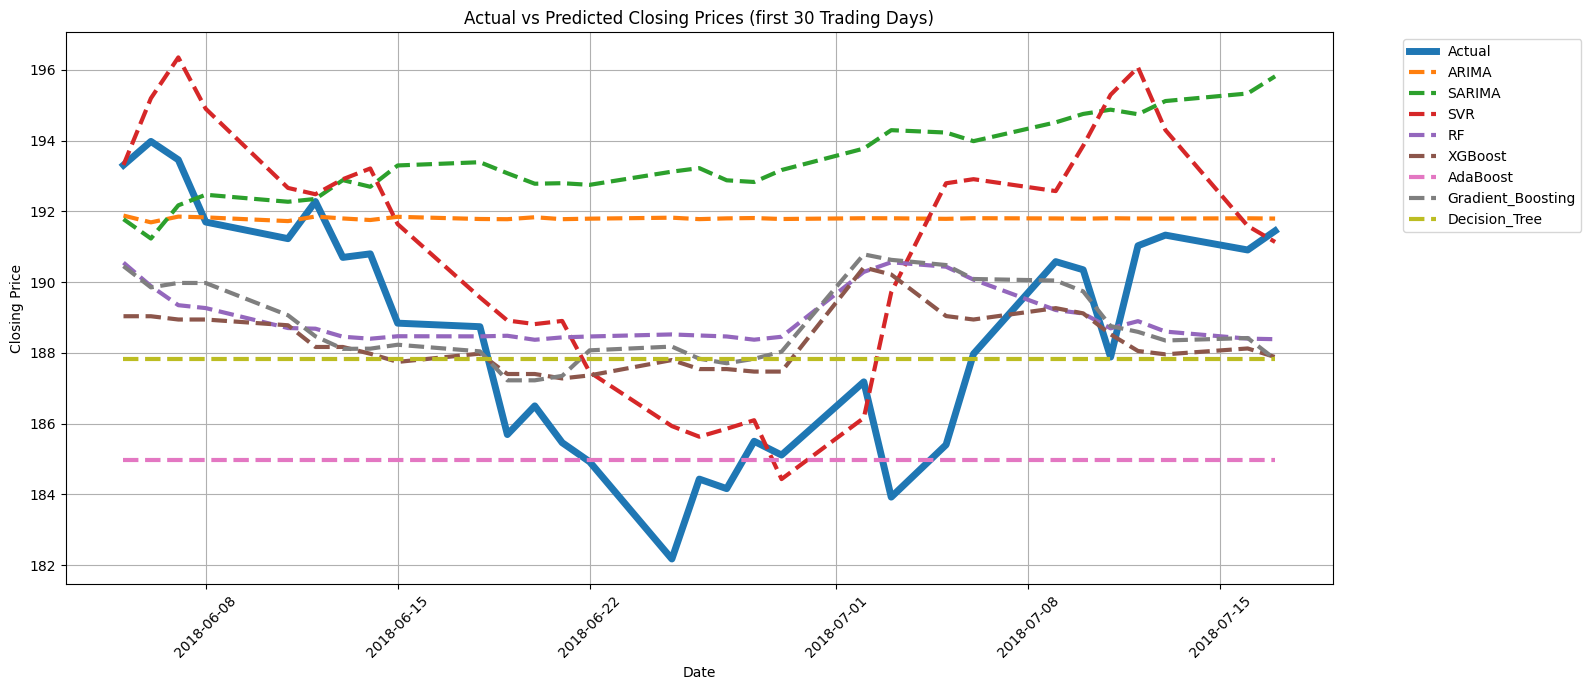

In [ ]:
#Visualising Actual vs Predicted Price
plt.figure(figsize=(16,7))
plt.plot(comparison_df['Date'],comparison_df['Actual'],
         label='Actual',linewidth=5)

for column in comparison_df.columns[2:]:
  plt.plot(comparison_df['Date'], comparison_df[column],
           label=column,linestyle='--',linewidth=3)
plt.title('Actual vs Predicted Closing Prices (first 30 Trading Days)')
plt.xlabel('Date')
plt.ylabel('Closing Price')
plt.legend(bbox_to_anchor=(1.05,1), loc='upper left')
plt.xticks(rotation = 45)
plt.grid(True)
plt.tight_layout()
plt.show()

So , based on the 30-trading day fixed origin forecast comparison, SVR demonstrates the closest predictions to Actual Apple closing prices overall. It achieved the lowest MAE(2.5914) and MAPE(1.3798%) among the evaluated models.

**Validate SVR**

In [ ]:
#Create validation split
val_train = train.iloc[:-30].copy()
val = train.iloc[-30:].copy()

print("Training Shape: ",val_train.shape)
print("Validation date: ",val.shape)

print("Training period: ",
      val_train['Date'].min(), "to", val_train['Date'].max())

print("Validation period: ",
      val['Date'].min(), "to", val['Date'].max())

Training Shape:  (1553, 20)
Validation date:  (30, 20)
Training period:  2012-02-17 00:00:00 to 2018-04-20 00:00:00
Validation period:  2018-04-23 00:00:00 to 2018-06-04 00:00:00


**Train a new SVR Model**

In [ ]:
#Select features and target
x_val_train = val_train[features]
y_val_train = val_train['Close']

#Scale the features
val_scaler = StandardScaler()
x_val_train_scaled = val_scaler.fit_transform(x_val_train)

#Train SVR
val_svr_model = SVR(
    kernel = 'rbf',
    C = 100,
    gamma = 'scale',
    epsilon = 0.1
)

val_svr_model.fit(x_val_train_scaled, y_val_train)

SVR(C=100)

In [ ]:
#Generate recursive predictions
history = val_train['Close'].tail(30).tolist()
val_future_dates = val['Date'].reset_index(drop = True)
svr_val_predictions = []
for date in val_future_dates:
  input_features = create_forecast_features(date, history)
  input_scaled = val_scaler.transform(input_features)
  prediction = val_svr_model.predict(input_scaled)[0]
  svr_val_predictions.append(prediction)
  history.append(prediction)
print("Total validation predictions: ",len(svr_val_predictions))
print(("First 5 predictions: ", svr_val_predictions[:5]))

Total validation predictions:  30
('First 5 predictions: ', [np.float64(169.19180978462146), np.float64(169.76366935492638), np.float64(168.3250229517679), np.float64(166.98358547150966), np.float64(165.77384684985293)])


In [ ]:
#Evaluating the validation prediction
from sklearn.metrics import mean_absolute_error, mean_squared_error
y_val_actual = val['Close'].values
y_val_predicted = np.array(svr_val_predictions)
val_mae = mean_absolute_error(y_val_actual, y_val_predicted)
val_rmse = np.sqrt(
    mean_squared_error(y_val_actual, y_val_predicted)
)
val_mape = np.mean(
    np.abs(y_val_actual - y_val_predicted) / np.abs(y_val_actual)
)*100

print("Validation MAE: ", val_mae)
print("Validation RMSE: ",val_rmse)
print("Validation MAPE: ",val_mape)

Validation MAE:  12.606472059786979
Validation RMSE:  14.318747711352508
Validation MAPE:  6.78854701084062


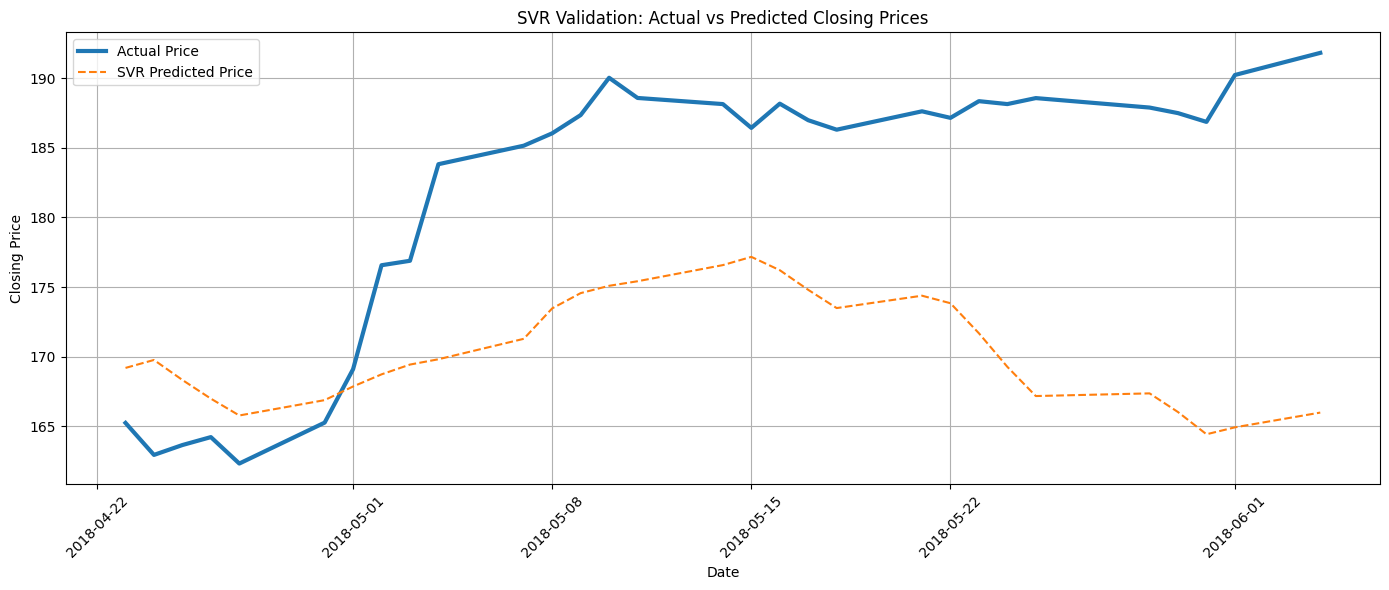

In [ ]:
#Visualising validation predictions
plt.figure(figsize=(14,6))
plt.plot(val['Date'], y_val_actual, label='Actual Price', linewidth = 3)
plt.plot(val['Date'], y_val_predicted, label='SVR Predicted Price', linestyle='--')

plt.title("SVR Validation: Actual vs Predicted Closing Prices")
plt.xlabel('Date')
plt.ylabel('Closing Price')
plt.legend()
plt.xticks(rotation = 45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
validation_comparison = pd.DataFrame({
    'Date': val['Date'].values,
    'Actual': y_val_actual,
    'Predicted': y_val_predicted
})

validation_comparison['Error'] = (
    validation_comparison['Actual'] -
    validation_comparison['Predicted']
)

validation_comparison.head(10)

,Date,Actual,Predicted,Error
0,2018-04-23,165.240005,169.191810,-3.951805
1,2018-04-24,162.940002,169.763669,-6.823667
2,2018-04-25,163.649994,168.325023,-4.675029
3,2018-04-26,164.220001,166.983585,-2.763584
4,2018-04-27,162.320007,165.773847,-3.453840
5,2018-04-30,165.259995,166.876569,-1.616574
6,2018-05-01,169.100006,167.857482,1.242524
7,2018-05-02,176.570007,168.728667,7.841340
8,2018-05-03,176.889999,169.432084,7.457915
9,2018-05-04,183.830002,169.813812,14.016190


Hyperparameter tuning of SVR

In [ ]:

import numpy as np
import pandas as pd
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from itertools import product

# 1. Define parameter combinations
C_values = [10, 50, 100, 200, 500]
gamma_values = ['scale', 0.01, 0.1, 1]
epsilon_values = [0.01, 0.1, 0.5, 1]

results = []

# 2. Try every parameter combination
for C, gamma, epsilon in product(
    C_values, gamma_values, epsilon_values
):

    # Prepare training data
    X_val_train = val_train[features]
    y_val_train = val_train['Close']

    # Scale features
    val_scaler = StandardScaler()
    X_val_train_scaled = val_scaler.fit_transform(X_val_train)

    # Train SVR
    model = SVR(
        kernel='rbf',
        C=C,
        gamma=gamma,
        epsilon=epsilon
    )

    model.fit(X_val_train_scaled, y_val_train)

    # 3. Generate recursive predictions
    history = val_train['Close'].tail(30).tolist()

    predictions = []

    for date in val_future_dates:

        input_features = create_forecast_features(
            date, history
        )

        input_scaled = val_scaler.transform(input_features)

        prediction = model.predict(input_scaled)[0]

        predictions.append(prediction)

        history.append(prediction)

    # 4. Calculate evaluation metrics
    actual = val['Close'].values
    predicted = np.array(predictions)

    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    mape = np.mean(
        np.abs((actual - predicted) / actual)
    ) * 100

    # 5. Store results
    results.append({
        'C': C,
        'Gamma': gamma,
        'Epsilon': epsilon,
        'MAE': mae,
        'RMSE': rmse,
        'MAPE': mape
    })

# 6. Create comparison table
svr_results = pd.DataFrame(results)

svr_results = svr_results.sort_values(
    by='MAE',
    ascending=True
).reset_index(drop=True)

# 7. Display results
print("Top 10 SVR Parameter Combinations:")
display(svr_results.head(10))

print("\nBest Parameters:")
print(svr_results.iloc[0])


Top 10 SVR Parameter Combinations:


,C,Gamma,Epsilon,MAE,RMSE,MAPE
0,100,0.01,0.50,10.351435,11.158138,5.605214
1,200,0.01,0.50,10.503166,11.367758,5.680693
2,500,0.01,0.01,10.753719,11.609793,5.815956
3,200,0.01,0.10,10.793675,11.700371,5.832819
4,500,0.01,0.10,10.857559,11.769291,5.866540
5,200,0.01,0.01,10.874587,11.800532,5.874706
6,100,0.01,0.10,11.046639,11.944778,5.973536
7,50,0.01,0.01,11.051170,11.900182,5.983812
8,500,0.01,0.50,11.098374,12.090752,5.990515
9,50,0.01,0.50,11.099843,11.973193,6.007841



Best Parameters:
C                100
Gamma           0.01
Epsilon          0.5
MAE        10.351435
RMSE       11.158138
MAPE        5.605214
Name: 0, dtype: object


In [ ]:
#Creating a Final tuned SVR model with best parameters
final_scaler = StandardScaler()
x_train_scaled = final_scaler.fit_transform(x_train)
final_svr_model = SVR(
    kernel = 'rbf',
    C = 100,
    gamma = 0.01,
    epsilon = 0.5
)
final_svr_model.fit(x_train_scaled, y_train)

SVR(C=100, epsilon=0.5, gamma=0.01)

In [ ]:
#Genearte predictions for 30 days
history = train['Close'].tail(30).tolist()
future_dates = test['Date'].iloc[:30].reset_index(drop=True)
final_svr_predictions = []
for date in future_dates:
  input_features = create_forecast_features(date, history)
  input_scaled = final_scaler.transform(input_features)
  prediction = final_svr_model.predict(input_scaled)[0]
  final_svr_predictions.append(prediction)
  history.append(prediction)


In [ ]:
#Checking the predictions
print("First 10 SVR Predictions: ")
print(final_svr_predictions[:10])

print("\nTotal predictions: ",len(final_svr_predictions))

First 10 SVR Predictions: 
[np.float64(191.28585734901026), np.float64(191.6876126434649), np.float64(191.85807244372486), np.float64(191.48524121464368), np.float64(191.37417999821298), np.float64(191.9384133078409), np.float64(192.50395814384711), np.float64(192.7343861995534), np.float64(192.32269213566903), np.float64(192.04456020321294)]

Total predictions:  30


In [ ]:
#Evaluate the tuned SVR model
final_svr_mae = mean_absolute_error(
    test['Close'].iloc[:30],
    final_svr_predictions
)

final_svr_rmse = np.sqrt(
    mean_squared_error(
        test['Close'].iloc[:30],
        final_svr_predictions
    )
)
final_svr_mape = np.mean(
    np.abs(test['Close'].iloc[:30].values - final_svr_predictions)
    / test['Close'].iloc[:30].values
) * 100

print("Tuned SVR Model Performance")
print("-----------------------------")
print("MAE: ",final_svr_mae)
print("RMSE: ",final_svr_rmse)
print("MAPE: ",final_svr_mape)

Tuned SVR Model Performance
-----------------------------
MAE:  2.99341379097834
RMSE:  3.8717049244093844
MAPE:  1.6066895264713283


In [ ]:
print("Final SVR Parameters:")
print(final_svr_model.get_params())

print("\nDifference between original and tuned predictions:")
print(np.max(np.abs(
    np.array(final_svr_predictions) -
    np.array(svr_recursive_predictions)
)))

Final SVR Parameters:
{'C': 100, 'cache_size': 200, 'coef0': 0.0, 'degree': 3, 'epsilon': 0.5, 'gamma': 0.01, 'kernel': 'rbf', 'max_iter': -1, 'shrinking': True, 'tol': 0.001, 'verbose': False}

Difference between original and tuned predictions:
4.9471944571006645


In [ ]:
final_comparison = pd.DataFrame({
    'Model': [
        'ARIMA',
        'SARIMA',
        'Original SVR',
        'Tuned SVR',
        'Random Forest',
        'XGBoost',
        'AdaBoost',
        'Gradient Boosting',
        'Decision Tree'
    ],

    'MAE': [
        3.6188,
        5.2277,
        2.5914,
        final_svr_mae,
        2.9223,
        2.7879,
        3.9473,
        2.7112,
        2.9728
    ],

    'RMSE': [
        4.5954,
        6.0023,
        3.2384,
        final_svr_rmse,
        3.2677,
        3.1292,
        4.8574,
        3.1031,
        3.3478
    ],

    'MAPE': [
        1.9444,
        2.7987,
        1.3798,
        final_svr_mape,
        1.5558,
        1.4787,
        2.0694,
        1.4421,
        1.5728
    ]
})

display(final_comparison.sort_values('MAE').reset_index(drop=True))

,Model,MAE,RMSE,MAPE
0,Original SVR,2.591400,3.238400,1.37980
1,Gradient Boosting,2.711200,3.103100,1.44210
2,XGBoost,2.787900,3.129200,1.47870
3,Random Forest,2.922300,3.267700,1.55580
4,Decision Tree,2.972800,3.347800,1.57280
5,Tuned SVR,2.993414,3.871705,1.60669
6,ARIMA,3.618800,4.595400,1.94440
7,AdaBoost,3.947300,4.857400,2.06940
8,SARIMA,5.227700,6.002300,2.79870


In [ ]:
prediction_comparison = pd.DataFrame({
    'Date': test['Date'].iloc[:30].values,
    'Actual': test['Close'].iloc[:30].values,
    'Original_SVR': svr_recursive_predictions,
    'Gradient_Boosting': gb_recursive_predictions,
    'XGBoost': xgb_recursive_predictions
})

display(prediction_comparison.head(10))

,Date,Actual,Original_SVR,Gradient_Boosting,XGBoost
0,2018-06-05,193.309998,193.314296,190.452561,189.035965
1,2018-06-06,193.979996,195.199954,189.852181,189.035736
2,2018-06-07,193.460007,196.355928,189.977604,188.943161
3,2018-06-08,191.699997,194.902635,189.975599,188.943161
4,2018-06-11,191.229996,192.664355,189.063229,188.779922
5,2018-06-12,192.279999,192.486296,188.468213,188.166412
6,2018-06-13,190.699997,192.911163,188.113224,188.166412
7,2018-06-14,190.800003,193.214571,188.118483,187.975449
8,2018-06-15,188.839996,191.640369,188.229669,187.743820
9,2018-06-18,188.740005,189.567617,188.042396,187.978592


**Model Selection for Deployment**

In [ ]:
final_model = SVR(
    kernel = 'rbf',
    C = 100,
    gamma = 'scale',
    epsilon = 0.1
)

In [ ]:
import pickle

with open('model.pkl','wb') as file:
  pickle.dump(svr_model, file)
with open('scaler.pkl', 'wb') as file:
  pickle.dump(scaler, file)

print("Model and Scaler saved successfully!")

Model and Scaler saved successfully!


In [ ]:
#Saving the historical dataset
historical_data = df[['Date','Open','High','Low','Close','Adj Close','Volume']].copy()
historical_data.to_csv("historical_data.csv",index = False)
print("Historical data saved successfully!")

Historical data saved successfully!
